In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Problem 0

In [2]:
t = np.linspace(0,np.pi*100,int(1e5))
N = 10+np.sin(t)
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N

# Problem 1
## Part a

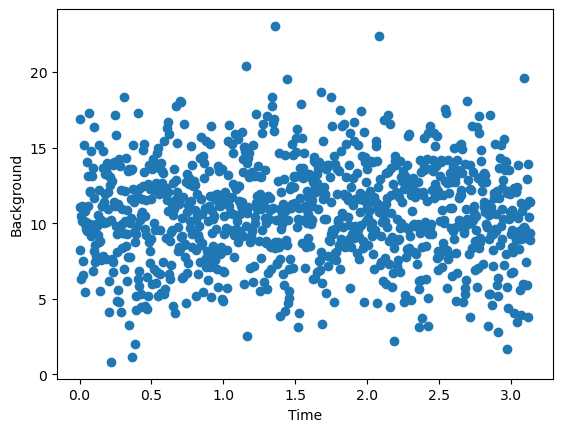

In [3]:
plt.plot(t[:1000], bkgd[:1000], 'o')
plt.xlabel("Time")
plt.ylabel("Background")
plt.show()

## Part b

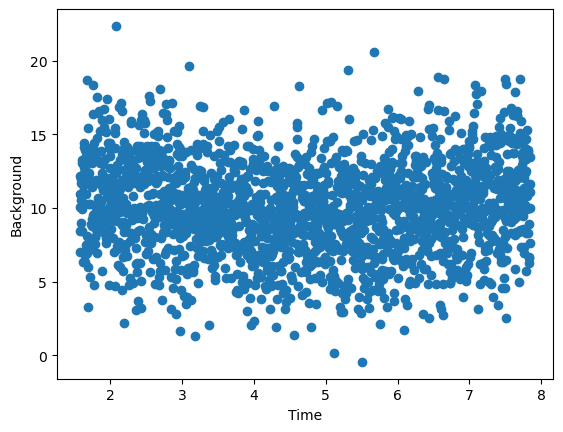

In [4]:
def subsets_plot(start, num_points):
    plt.plot(t[start:start + num_points], bkgd[start:start + num_points], 'o')
    plt.xlabel("Time")
    plt.ylabel("Background")
    plt.show()

subsets_plot(500, 2000)

## Part c

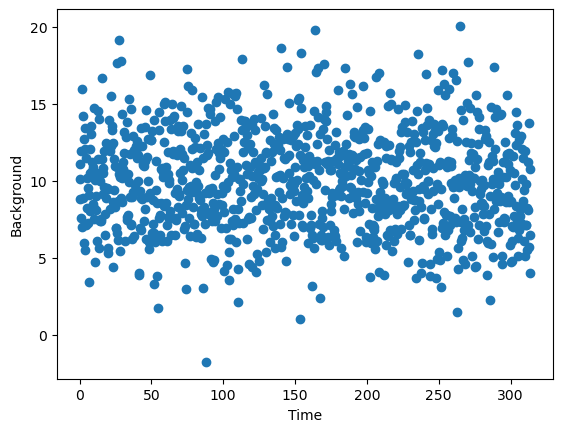

In [5]:
plt.plot(t[::100], bkgd[::100], 'o')
plt.xlabel("Time")
plt.ylabel("Background")
plt.show()

# Problem 2
## Part a

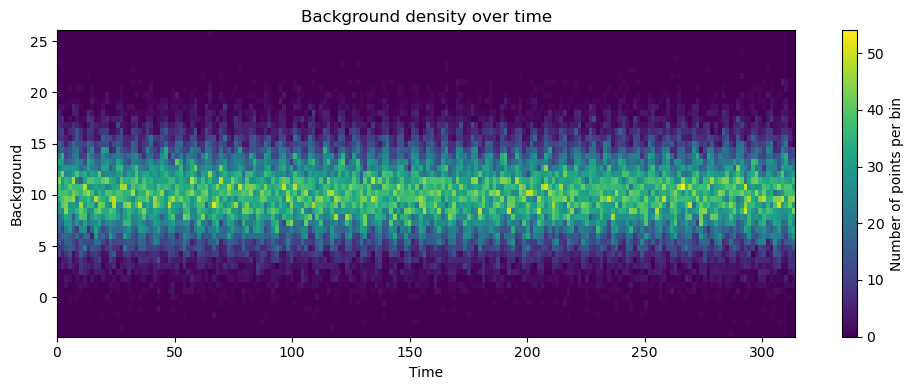

In [6]:
plt.figure(figsize=(10, 4))
plt.hist2d(t, bkgd, bins=(200, 50), cmap='viridis')
plt.colorbar(label='Number of points per bin')
plt.xlabel('Time')
plt.ylabel('Background')
plt.title('Background density over time')
plt.tight_layout()
plt.show()

## Part b

The horizontal axis is time, and the vertical axis is the background data. Each rectangular bin counts how many data points fall in its time and background ranges. The colorbar gives this count: yellow bins contain more points, while dark purple bins contain fewer or no points. These are counts per bin, not normalized probabilities.

I compared 50, 200, and 500 time bins with 50 background bins. With 50 time bins, the time variation is washed out; with 500, the plot looks noisier. I used 200 time bins as a compromise. Most points lie near a background value of 10, with a small periodic variation and fewer points far from the center.

# Problem 3
## Part a

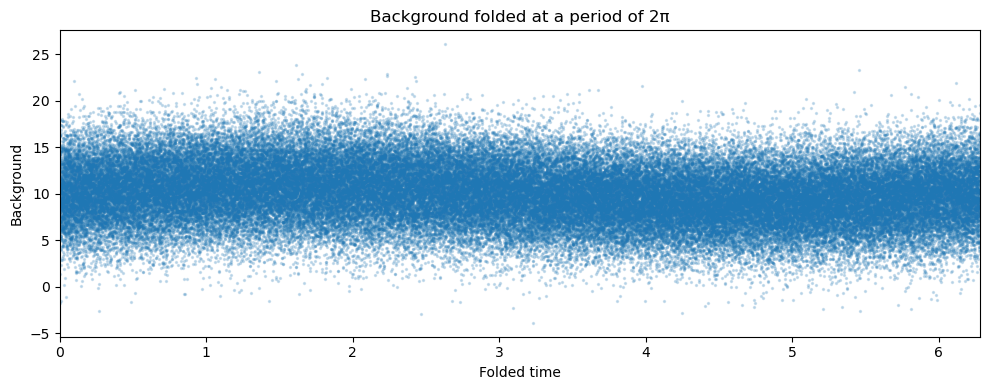

In [7]:
t_folded = t % (2 * np.pi)
plt.figure(figsize=(10, 4))
plt.scatter(t_folded, bkgd, s=2, alpha=0.2)
plt.xlabel('Folded time')
plt.ylabel('Background')
plt.title('Background folded at a period of 2π')
plt.xlim(0, 2 * np.pi)
plt.tight_layout()
plt.show()

## Part b

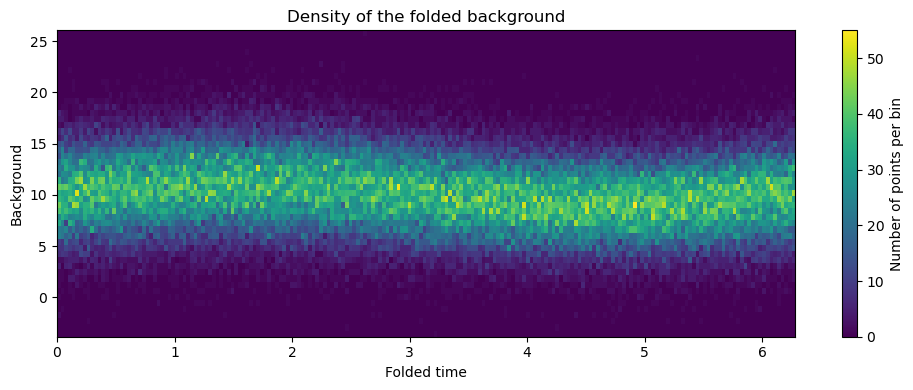

In [8]:
plt.figure(figsize=(10, 4))
counts, time_edges, value_edges, image = plt.hist2d(
    t_folded, bkgd, bins=(200, 50), cmap='viridis')
plt.colorbar(label='Number of points per bin')
plt.xlabel('Folded time')
plt.ylabel('Background')
plt.title('Density of the folded background')
plt.tight_layout()
plt.show()

## Part c

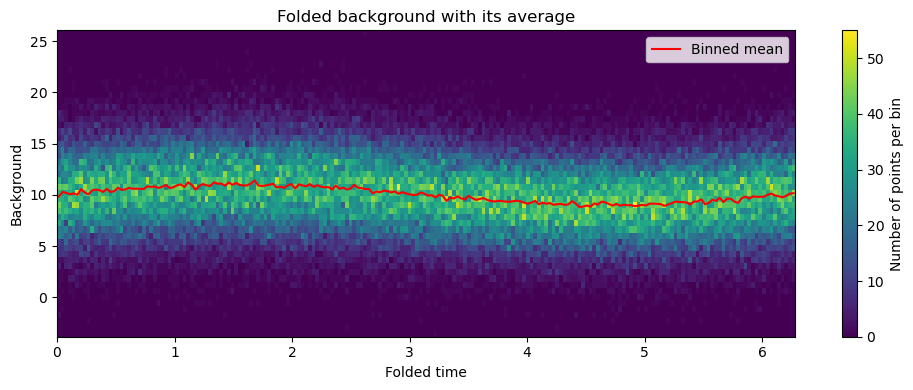

In [9]:
time_centers = (time_edges[:-1] + time_edges[1:]) / 2
value_centers = (value_edges[:-1] + value_edges[1:]) / 2
mean_background = (counts @ value_centers) / counts.sum(axis=1)

plt.figure(figsize=(10, 4))
plt.hist2d(t_folded, bkgd, bins=(time_edges, value_edges), cmap='viridis')
plt.colorbar(label='Number of points per bin')
plt.plot(time_centers, mean_background, 'r-', label='Binned mean')
plt.xlabel('Folded time')
plt.ylabel('Background')
plt.title('Folded background with its average')
plt.legend()
plt.tight_layout()
plt.show()